# Model evaluation: label sensitivity, calibration, explainability

Evaluates the logistic regression baseline (`log-reg-model.ipynb`) on the 2024 train / 2025 test split.
Baseline reference: Acc 0.815, F1 0.789, ROC-AUC 0.893. Three checks:

1. **Label sensitivity.** Is the `attendance_pct >= 0.90` "high" cutoff defensible.
2. **Calibration.** Does a predicted 0.70 correspond to a real 70% chance.
3. **SHAP.** Which game level factors drive a prediction.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve

X_train = pd.read_csv("../data/X_train.csv"); X_test = pd.read_csv("../data/X_test.csv")
y_train = pd.read_csv("../data/y_train.csv").squeeze(); y_test = pd.read_csv("../data/y_test.csv").squeeze()

def make_pre(X):
    cat = X.select_dtypes(include=["object","str","bool","category"]).columns.tolist()
    num = [c for c in X.columns if c not in cat]
    return ColumnTransformer([
        ("num", Pipeline([("i",SimpleImputer(strategy="median")),("s",StandardScaler())]), num),
        ("cat", Pipeline([("i",SimpleImputer(strategy="most_frequent")),("e",OneHotEncoder(handle_unknown="ignore"))]), cat)])

_, p_full = (lambda a,b: (None, Pipeline([("pre",make_pre(a)),("clf",LogisticRegression(max_iter=1000,random_state=42))]).fit(a,y_train).predict_proba(b)[:,1]))(X_train, X_test)

## 1. Label sensitivity

`high_attendance` is `attendance_pct >= 0.90`. Redefine the label at several cutoffs, retrain, score on 2025.

In [2]:
feat = pd.read_csv("../data/features.csv")
clean = pd.read_csv("../data/full_dataset_clean.csv")[["id","attendance_pct"]]
d = feat.merge(clean, on="id", how="left").dropna(subset=["attendance_pct"])
tr, te = d[d.season==2024], d[d.season==2025]
drop_cols = ["id","season","high_attendance","attendance_pct"]

rows = []
for cut in [0.80, 0.85, 0.90, 0.95, 1.00]:
    ytr = (tr["attendance_pct"]>=cut).astype(int); yte = (te["attendance_pct"]>=cut).astype(int)
    m = Pipeline([("pre",make_pre(tr.drop(columns=drop_cols))),
                  ("clf",LogisticRegression(max_iter=1000,random_state=42))]).fit(tr.drop(columns=drop_cols), ytr)
    pr = m.predict_proba(te.drop(columns=drop_cols))[:,1]
    rows.append({"cutoff":cut, "pos rate":round(yte.mean(),2),
                 "accuracy":round(accuracy_score(yte,pr>=.5),3),
                 "F1":round(f1_score(yte,pr>=.5),3),
                 "ROC-AUC":round(roc_auc_score(yte,pr),3)})
sweep = pd.DataFrame(rows); sweep

,cutoff,pos rate,accuracy,F1,ROC-AUC
0,0.80,0.61,0.852,0.874,0.926
1,0.85,0.52,0.824,0.829,0.902
2,0.90,0.44,0.815,0.789,0.893
3,0.95,0.36,0.840,0.773,0.895
4,1.00,0.22,0.865,0.669,0.882


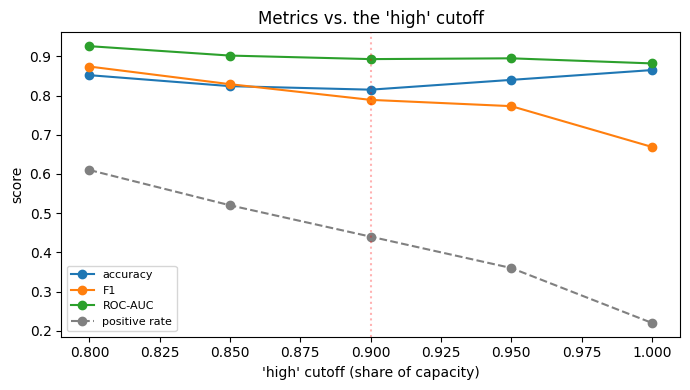

In [3]:
fig, ax = plt.subplots(figsize=(7,4))
for col in ["accuracy","F1","ROC-AUC"]:
    ax.plot(sweep["cutoff"], sweep[col], marker="o", label=col)
ax.plot(sweep["cutoff"], sweep["pos rate"], ls="--", color="gray", marker="o", label="positive rate")
ax.axvline(0.90, color="red", alpha=0.3, ls=":")
ax.set_xlabel("'high' cutoff (share of capacity)"); ax.set_ylabel("score")
ax.set_title("Metrics vs. the 'high' cutoff"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Accuracy peaks at the 1.00 cutoff (0.865) only because positives get rare (22%), while F1 falls to 0.67.
AUC stays 0.88 to 0.93 across all cutoffs. The 0.90 cutoff gives near balanced classes (44%).
Defend it with F1 and AUC, not accuracy.

## 2. Calibration

Bin the full model's predicted probabilities against the actual high attendance rate per bin.

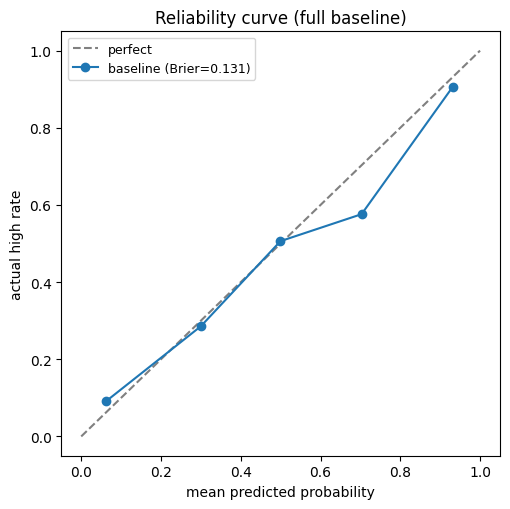

In [4]:
brier = brier_score_loss(y_test, p_full)
frac_pos, mean_pred = calibration_curve(y_test, p_full, n_bins=5, strategy="uniform")
fig, ax = plt.subplots(figsize=(5.2,5.2))
ax.plot([0,1],[0,1], ls="--", color="gray", label="perfect")
ax.plot(mean_pred, frac_pos, marker="o", label=f"baseline (Brier={brier:.3f})")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("actual high rate")
ax.set_title("Reliability curve (full baseline)"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

Well calibrated overall (Brier 0.131). The 0.6 to 0.8 bin is mildly overconfident: it predicts about
0.70 but only about 0.58 of those games were high. Fix with a calibration pass if a score is displayed.

## 3. Explainability (SHAP)

Run on the no team names model (AUC 0.838) so the drivers are game factors, not team identity.

Background dataset has 815 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=815 when initializing the masker.


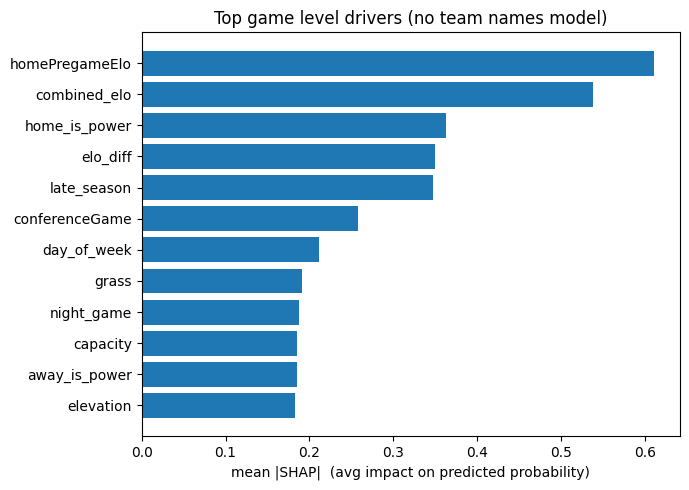

In [5]:
import shap
Xtr_n = X_train.drop(columns=["homeTeam","awayTeam"]); Xte_n = X_test.drop(columns=["homeTeam","awayTeam"])
pre_n = make_pre(Xtr_n); Xtr_enc = pre_n.fit_transform(Xtr_n); Xte_enc = pre_n.transform(Xte_n)
names = [n.split("__",1)[-1] for n in pre_n.get_feature_names_out()]
clf_n = LogisticRegression(max_iter=1000, random_state=42).fit(Xtr_enc, y_train)
dense = lambda M: M.toarray() if hasattr(M,"toarray") else M
sv = shap.LinearExplainer(clf_n, dense(Xtr_enc)).shap_values(dense(Xte_enc))
imp = pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False)

top = imp.head(12)[::-1]
fig, ax = plt.subplots(figsize=(7,5)); ax.barh(top.index, top.values)
ax.set_xlabel("mean |SHAP|  (avg impact on predicted probability)")
ax.set_title("Top game level drivers (no team names model)")
plt.tight_layout(); plt.show()

Top drivers: home Elo, combined Elo, power conference, Elo gap, late season. Weather and kickoff timing
matter far less. Team strength and matchup quality drive turnout.

## Findings

1. Defend the 0.90 cutoff with F1 and AUC. Accuracy only rises at stricter cutoffs because positives get rare.
2. Model is well calibrated except the 0.6 to 0.8 range (predicts 0.70, actual 0.58). Fix before displaying a score.
3. Drivers are team strength and matchup (Elo, power conference, Elo gap), then season timing.

For the coach meeting: decide label vs. score output (score needs the calibration fix), and which model is
"insights" (no team names) vs. "prediction" (full / school history).